In [3]:
import gc
import time
import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Carga del dataset con Feature Engineering (lags y deltas)
data_path = "competencia_02_fe.csv"
print("Cargando el dataset procesado...")
if data_path.endswith('.csv'):
    data = pd.read_csv(data_path)
else:
    data = pd.read_parquet(data_path)

# Parámetros de negocio para la ganancia en test
ganancia_acierto = 1_072_500
costo_estimulo = 27_500

# Meses según especificación de la cátedra
meses_train = [201903, 201904, 201905, 201906]
mes_validacion = 201908
mes_test = 201910

# Semillas
semilla = 777781
np.random.seed(semilla)
semillas = np.random.choice(1000000, size=50, replace=False).tolist()

# Target binario (BAJA+1 y BAJA+2 combinadas)
data['clase_binaria'] = np.where(data['clase_ternaria'].isin(['BAJA+1', 'BAJA+2']), 1, 0)

# Selección automática de variables numéricas (excluyendo metadatos y targets)
cols_meta = ["numero_de_cliente", "foto_mes", "clase_ternaria", "clase_binaria"]
cols_features = [
    c for c in data.columns 
    if c not in cols_meta and pd.api.types.is_numeric_dtype(data[c])
]

print(f"Variables seleccionadas para entrenar: {len(cols_features)}")

# Filtrado por meses
train_data = data[data["foto_mes"].isin(meses_train)][cols_meta + cols_features]
val_data   = data[data["foto_mes"] == mes_validacion][cols_meta + cols_features]
test_data  = data[data["foto_mes"] == mes_test][cols_meta + cols_features]

del data
gc.collect()

# Datasets para LightGBM
X_train = train_data[cols_features]
y_train_binaria = train_data["clase_binaria"]

X_val = val_data[cols_features]
y_val_binaria = val_data["clase_binaria"]

X_test = test_data[cols_features]
y_test_binaria = test_data["clase_binaria"]

train_data_lgb = lgb.Dataset(X_train, label=y_train_binaria, free_raw_data=True)
val_data_lgb   = lgb.Dataset(X_val, label=y_val_binaria, reference=train_data_lgb, free_raw_data=True)

# ==============================================================================
# OPTIMIZACIÓN CON OPTUNA (Métrica: AUC)
# ==============================================================================
sss_opt = StratifiedShuffleSplit(
    n_splits=5, test_size=0.3, random_state=semillas[0]
)

def objective(trial):
    num_leaves = trial.suggest_int("num_leaves", 8, 100)
    learning_rate = trial.suggest_float("learning_rate", 0.005, 0.3)
    min_data_in_leaf = trial.suggest_int("min_data_in_leaf", 1, 1000)
    feature_fraction = trial.suggest_float("feature_fraction", 0.1, 1.0)
    bagging_fraction = trial.suggest_float("bagging_fraction", 0.1, 1.0)
    bagging_freq = 1 # >= 1 como pidieron

    params = {
        "objective": "binary",
        "metric": "auc",               # Métrica AUC para BO y early stopping
        "boosting_type": "gbdt",
        "first_metric_only": True,
        "boost_from_average": True,
        "feature_pre_filter": False,
        "max_bin": 31,
        "num_leaves": num_leaves,
        "learning_rate": learning_rate,
        "min_data_in_leaf": min_data_in_leaf,
        "feature_fraction": feature_fraction,
        "bagging_fraction": bagging_fraction,
        "bagging_freq": bagging_freq,
        "seed": semillas[0],
        "verbose": -1
    }

    cv_results = lgb.cv(
        params,
        train_data_lgb,
        num_boost_round=3000,
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(50 + 5 / learning_rate), verbose=False
            )
        ],
        folds=sss_opt.split(X_train, y_train_binaria),
        seed=semillas[0],
    )

    # Optimizamos maximizando el AUC medio de validación cruzada
    max_auc = max(cv_results["valid auc-mean"])
    best_iter = cv_results["valid auc-mean"].index(max_auc) + 1

    trial.set_user_attr("best_iter", best_iter)
    return max_auc

storage_name = "sqlite:///optimization_lgbm_auc.db"
study_name = "base_lgbm_auc_fe"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
)

start_time = time.time()
study.optimize(objective, n_trials=50)
elapsed_time = time.time() - start_time

print(f"\n--- OPTIMIZACIÓN FINALIZADA ---")
print(f"Minutos: {elapsed_time / 60:.2f}")
print(f"Mejor AUC encontrado: {study.best_value:.5f}")
print(f"Mejores hiperparámetros: {study.best_params}")



Cargando el dataset procesado...
Variables seleccionadas para entrenar: 760


[I 2026-11-16 14:43:53,281] Using an existing study with `study_name='base_lgbm_auc_fe'` instead of creating a new one.
[I 2026-11-16 15:14:06,533] Trial 19 finished with value: 0.9531649551183661 and parameters: {'num_leaves': 89, 'learning_rate': 0.03487561359812556, 'min_data_in_leaf': 654, 'feature_fraction': 0.4183991218049984, 'bagging_fraction': 0.951217010418872}. Best is trial 19 with value: 0.9531649551183661.
[I 2026-11-16 15:23:51,195] Trial 20 finished with value: 0.9480648890726513 and parameters: {'num_leaves': 73, 'learning_rate': 0.10745496063686596, 'min_data_in_leaf': 982, 'feature_fraction': 0.46563370730359877, 'bagging_fraction': 0.9223091974033922}. Best is trial 19 with value: 0.9531649551183661.
[I 2026-11-16 15:37:29,319] Trial 21 finished with value: 0.9509251378276107 and parameters: {'num_leaves': 75, 'learning_rate': 0.05284777195827439, 'min_data_in_leaf': 531, 'feature_fraction': 0.8325541898958315, 'bagging_fraction': 0.9250530565941989}. Best is trial 

KeyboardInterrupt: 

In [4]:
# Ahora tengo que cambiar y_test_ganancia = np.where(test_data["clase_ternaria"] == "BAJA+2", 1, 0)

# ==============================================================================
# ENTRENAMIENTO FINAL Y EVALUACIÓN DE GANANCIA EN TEST (201910)
# ==============================================================================

# 1. Target estricto de negocio para test (201910): SOLO 'BAJA+2' gana dinero
y_test_ganancia = np.where(test_data["clase_ternaria"] == "BAJA+2", 1, 0)

# 2. Recuperar los mejores hiperparámetros de Optuna
best_params = study.best_params

final_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "boost_from_average": True,
    "feature_pre_filter": False,
    "max_bin": 31,
    "seed": semillas[0],
    "verbose": -1,
    **best_params
}

print("\nEntrenando el modelo final con los mejores hiperparámetros...")
final_model = lgb.train(
    final_params,
    train_data_lgb,
    num_boost_round=3000,
    valid_sets=[val_data_lgb],
    callbacks=[
        lgb.early_stopping(stopping_rounds=int(50 + 5 / best_params["learning_rate"])),
        lgb.log_evaluation(period=50)
    ]
)

print(f"Iteración óptima alcanzada con early stopping en agosto: {final_model.best_iteration}")

# 3. Predicción de probabilidades en el mes de test (201910)
y_pred_test = final_model.predict(X_test)

# 4. Cálculo de la Ganancia en test (solo BAJA+2 suma ganancia_acierto)
ganancia_casos = (
    np.where(y_test_ganancia == 1, ganancia_acierto, 0)
    - np.where(y_test_ganancia == 0, costo_estimulo, 0)
)

ganancia_total = ganancia_casos[y_pred_test >= 0.025].sum()
cantidad_envios = (y_pred_test >= 0.025).sum()

print(f"\n--- EVALUACIÓN EN TEST (Mes {mes_test}) ---")
print(f"Cantidad de estímulos enviados: {cantidad_envios:,}")
print(f"Ganancia total real estimada: ${ganancia_total:,.2f}")




Entrenando el modelo final con los mejores hiperparámetros...
Training until validation scores don't improve for 193 rounds
[50]	valid_0's auc: 0.924108
[100]	valid_0's auc: 0.928064
[150]	valid_0's auc: 0.929674
[200]	valid_0's auc: 0.929395
[250]	valid_0's auc: 0.928208
[300]	valid_0's auc: 0.927426
Early stopping, best iteration is:
[136]	valid_0's auc: 0.929912
Iteración óptima alcanzada con early stopping en agosto: 136

--- EVALUACIÓN EN TEST (Mes 201910) ---
Cantidad de estímulos enviados: 8,182
Ganancia total real estimada: $258,995,000.00


In [6]:
# ==============================================================================
# ENSAMBLE DE 10 SEMILLAS (BAGGING) Y RECÁLCULO DE CORTE ÓPTIMO
# ==============================================================================

n_semillas = 10
semillas_ensemble = semillas[:n_semillas]

preds_val_list = []
preds_test_list = []

best_params = study.best_params

print(f"Entrenando ensamble de {n_semillas} modelos con distintas semillas...")
for i, semilla in enumerate(semillas_ensemble):
    print(f"-> Entrenando modelo {i+1}/{n_semillas} (Semilla: {semilla})...")
    
    params_seed = {
        "objective": "binary",
        "metric": "auc",
        "boosting_type": "gbdt",
        "boost_from_average": True,
        "feature_pre_filter": False,
        "max_bin": 31,
        "seed": semilla,
        "verbose": -1,
        **best_params
    }
    
    # Entrenamiento con early stopping individual en agosto (val_data_lgb)
    model_seed = lgb.train(
        params_seed,
        train_data_lgb,
        num_boost_round=3000,
        valid_sets=[val_data_lgb],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=int(50 + 5 / params_seed["learning_rate"]), 
                verbose=False
            )
        ]
    )
    
    # Guardar probabilidades predichas para validación y test
    preds_val_list.append(model_seed.predict(X_val))
    preds_test_list.append(model_seed.predict(X_test))

# Promediar las probabilidades de todos los modelos (Bagging)
y_pred_val_ens = np.mean(preds_val_list, axis=0)
y_pred_test_ens = np.mean(preds_test_list, axis=0)

# ==============================================================================
# RECALCULAR CORTE ÓPTIMO EN AGOSTO (201908) CON EL ENSAMBLE
# ==============================================================================
y_val_ganancia = np.where(val_data["clase_ternaria"] == "BAJA+2", 1, 0)
ganancia_casos_val = (
    np.where(y_val_ganancia == 1, ganancia_acierto, 0)
    - np.where(y_val_ganancia == 0, costo_estimulo, 0)
)

idx_orden_val = np.argsort(y_pred_val_ens)[::-1]
ganancia_acumulada_val = np.cumsum(ganancia_casos_val[idx_orden_val])

mejor_idx_ens = np.argmax(ganancia_acumulada_val)
optimo_envios_ens = mejor_idx_ens + 1
max_ganancia_ens_val = ganancia_acumulada_val[mejor_idx_ens]

print(f"\n--- ENSAMBLE EN VALIDACIÓN (Agosto 201908) ---")
print(f"Ganancia máxima en agosto: ${max_ganancia_ens_val:,.2f}")
print(f"Cantidad óptima de envíos (Top N): {optimo_envios_ens:,}")

# ==============================================================================
# APLICAR EL NUEVO CORTE EN OCTUBRE (201910)
# ==============================================================================
y_test_ganancia = np.where(test_data["clase_ternaria"] == "BAJA+2", 1, 0)
ganancia_casos_test = (
    np.where(y_test_ganancia == 1, ganancia_acierto, 0)
    - np.where(y_test_ganancia == 0, costo_estimulo, 0)
)

idx_orden_test = np.argsort(y_pred_test_ens)[::-1]
ganancia_test_ens = ganancia_casos_test[idx_orden_test][:optimo_envios_ens].sum()

print(f"\n--- ENSAMBLE EN TEST (Octubre 201910) ---")
print(f"Envíos realizados: {optimo_envios_ens:,}")
print(f"Ganancia total del ensamble: ${ganancia_test_ens:,.2f}")

Entrenando ensamble de 10 modelos con distintas semillas...
-> Entrenando modelo 1/10 (Semilla: 825860)...
-> Entrenando modelo 2/10 (Semilla: 307679)...
-> Entrenando modelo 3/10 (Semilla: 278024)...
-> Entrenando modelo 4/10 (Semilla: 863763)...
-> Entrenando modelo 5/10 (Semilla: 609429)...
-> Entrenando modelo 6/10 (Semilla: 735467)...
-> Entrenando modelo 7/10 (Semilla: 509382)...
-> Entrenando modelo 8/10 (Semilla: 985203)...
-> Entrenando modelo 9/10 (Semilla: 932617)...
-> Entrenando modelo 10/10 (Semilla: 256927)...

--- ENSAMBLE EN VALIDACIÓN (Agosto 201908) ---
Ganancia máxima en agosto: $212,107,500.00
Cantidad óptima de envíos (Top N): 4,607

--- ENSAMBLE EN TEST (Octubre 201910) ---
Envíos realizados: 4,607
Ganancia total del ensamble: $280,307,500.00


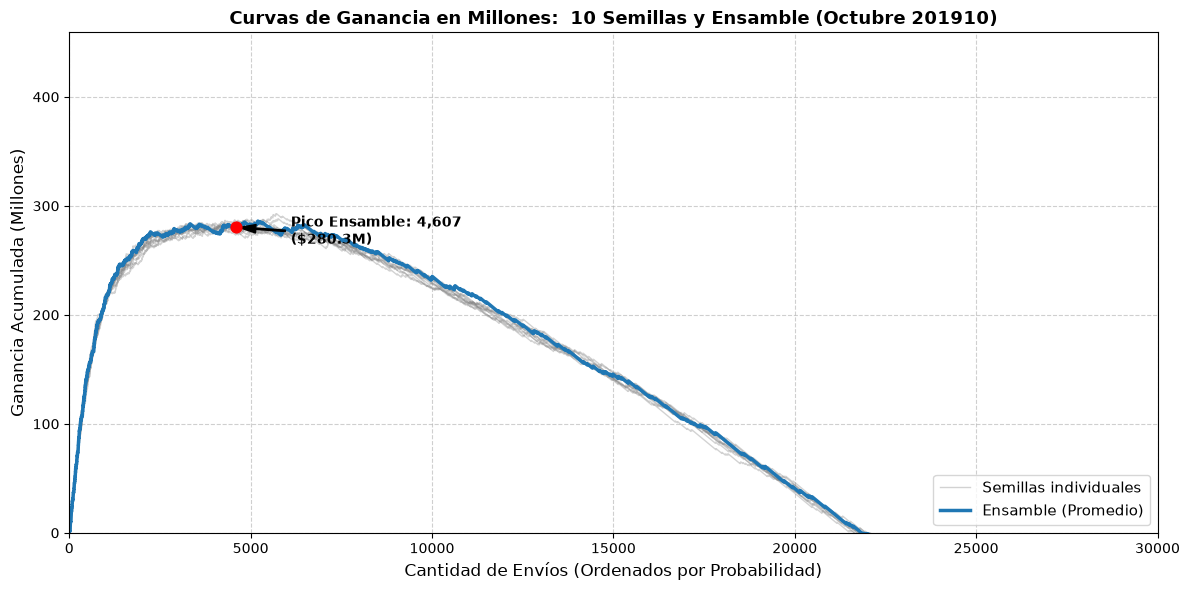

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Vector de ganancia real en test (Octubre 201910)
y_test_ganancia = np.where(test_data["clase_ternaria"] == "BAJA+2", 1, 0)
ganancia_casos_test = (
    np.where(y_test_ganancia == 1, ganancia_acierto, 0)
    - np.where(y_test_ganancia == 0, costo_estimulo, 0)
)
envios = np.arange(1, len(ganancia_casos_test) + 1)

plt.figure(figsize=(12, 6))

# 1. Graficar la curva de cada semilla individual (dividido por 1 millón)
for i, y_pred_seed in enumerate(preds_test_list):
  idx_orden_seed = np.argsort(y_pred_seed)[::-1]
  ganancia_seed = np.cumsum(ganancia_casos_test[idx_orden_seed]) / 1e6
  plt.plot(
      envios,
      ganancia_seed,
      color="gray",
      alpha=0.35,
      linewidth=1,
      label="Semillas individuales" if i == 0 else "",
  )

# 2. Graficar la curva del ensamble (dividido por 1 millón)
idx_orden_ens = np.argsort(y_pred_test_ens)[::-1]
ganancia_ens = np.cumsum(ganancia_casos_test[idx_orden_ens]) / 1e6
plt.plot(
    envios,
    ganancia_ens,
    color="#1f77b4",
    linewidth=2.5,
    label="Ensamble (Promedio)",
)

# Marcar el punto óptimo del ensamble (4,607 envíos)
optimo_idx = 4607 - 1
optimo_val_millones = ganancia_ens[optimo_idx]
plt.scatter(4607, optimo_val_millones, color="red", s=60, zorder=5)
plt.annotate(
    f"Pico Ensamble: 4,607\n(${optimo_val_millones:.1f}M)",
    xy=(4607, optimo_val_millones),
    xytext=(4607 + 1500, optimo_val_millones - 15),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontsize=10,
    fontweight="bold",
)


# Configuración de límites: sin negativos en Y y zoom en los primeros 30k envíos
plt.ylim(bottom=0)
plt.xlim(0, 30000)

plt.title(
    "Curvas de Ganancia en Millones:  10 Semillas y Ensamble (Octubre 201910)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Cantidad de Envíos (Ordenados por Probabilidad)", fontsize=12)
plt.ylabel("Ganancia Acumulada (Millones)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

